# RappiPlus: de datos a decisiones de negocio

Análisis end-to-end de un servicio de suscripción: calidad de datos, rentabilidad, funnel, cohortes y test A/B.

**Autora:** Gabriela López Larios · Analista de Datos  
Proyecto del Bootcamp de Análisis de Datos de TripleTen (2026) con datos simulados. Consulta el `README.md` del repositorio para ver el resumen de hallazgos.

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**

El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

---

In [1]:
# importar librerías
import pandas as pd
import numpy as np

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# explorar datasets (primeras filas)

print("--- ORDERS ---")
display(orders.head())

print("--- CATALOG ---")
display(catalog.head())

print("--- MARKETING ---")
display(marketing.head())

--- ORDERS ---


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


--- CATALOG ---


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


--- MARKETING ---


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [4]:
# Información general (tipos de datos y valores no nulos)

print("--- ORDERS ---")
orders.info()
print ()
print("--- CATALOG ---")
catalog.info()
print()
print("--- MARKETING ---")
marketing.info()

--- ORDERS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB

--- CATALOG ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column          

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [5]:
# 1. Limpieza de dataset ORDERS

# Impresión del estado inicial
print(f"Registros iniciales en orders: {len(orders)}")

# Conversión de fechas
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'])

# Limpieza de nulos numéricos clave
orders = orders.dropna(subset=['cantidad', 'precio_unitario', 'monto_descuento', 'nombre_producto'])

# Filtro de inconsistencias numéricas
orders = orders[
    (orders['cantidad'] > 0) & 
    (orders['precio_unitario'] > 0) & 
    (orders['monto_descuento'] >= 0)
]

# Validación de consistencia de montos
orders['monto_calculado'] = (orders['cantidad'] * orders['precio_unitario']) - orders['monto_descuento']

# Eliminación de duplicados
orders = orders.drop_duplicates()

# Normalización de categorías y tratamiento de nulos categóricos
orders['categoria_producto'] = orders['categoria_producto'].str.replace('Electronica', 'Electrónica')
orders['pais'] = orders['pais'].fillna('Desconocido')
orders['dispositivo'] = orders['dispositivo'].fillna('Desconocido')
orders['fuente_referencia'] = orders['fuente_referencia'].fillna('Desconocido')

print(f"Registros finales en orders: {len(orders)}")
orders.head(3)

Registros iniciales en orders: 25100
Registros finales en orders: 24916


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,monto_calculado
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electrónica,1.0,176.86,5.0,171.86,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98


In [6]:
# 2. Limpieza de dataset CATALOG

print(f"Registros iniciales en catalog: {len(catalog)}")

# Eliminación de duplicados
catalog = catalog.drop_duplicates()

# Estandarización de categorías
catalog['categoria_producto'] = catalog['categoria_producto'].str.replace('Electronica', 'Electrónica')

# Normalización de espacios en el nombre de producto para asegurar Joins limpios
catalog['nombre_producto'] = catalog['nombre_producto'].str.strip()

print(f"Registros finales en catalog: {len(catalog)}")
catalog.head(3)

Registros iniciales en catalog: 7
Registros finales en catalog: 7


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC


In [7]:
# 3. Limpieza de dataset MARKETING

print(f"Registros iniciales en marketing: {len(marketing)}")

# Conversión de fechas
marketing['fecha'] = pd.to_datetime(marketing['fecha'])

# Filtro de gastos no válidos
marketing = marketing[marketing['gasto'] >= 0]

# Eliminación de duplicados
marketing = marketing.drop_duplicates()

# Imputación inteligente de la columna 'canal' a partir de 'id_campaña'
marketing['canal'] = marketing['canal'].fillna(
    marketing['id_campaña'].str.rsplit('_', n=1).str[0]
)

print(f"Registros finales en marketing: {len(marketing)}")
marketing.head(3)

Registros iniciales en marketing: 1620
Registros finales en marketing: 1620


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01


In [8]:
print("=== ORDERS ===")
print(orders.info())
print()
print("=== CATALOG ===")
print(catalog.info())
print()
print("=== MARKETING ===")
print(marketing.info())

=== ORDERS ===
<class 'pandas.core.frame.DataFrame'>
Index: 24916 entries, 0 to 24999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           24916 non-null  object        
 1   id_usuario          24916 non-null  object        
 2   fecha_hora_pedido   24916 non-null  datetime64[ns]
 3   pais                24916 non-null  object        
 4   dispositivo         24916 non-null  object        
 5   fuente_referencia   24916 non-null  object        
 6   nombre_producto     24916 non-null  object        
 7   categoria_producto  24916 non-null  object        
 8   cantidad            24916 non-null  float64       
 9   precio_unitario     24916 non-null  float64       
 10  monto_descuento     24916 non-null  float64       
 11  monto_total         24916 non-null  float64       
 12  monto_calculado     24916 non-null  float64       
dtypes: datetime64[ns](1), float64(5), ob

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [9]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [10]:
# PARTE 1: RENTABILIDAD DEL NEGOCIO

# Unir orders con catalog para obtener el costo de los productos
orders_merged = orders.merge(
    catalog[['nombre_producto', 'costo_unitario']], 
    on='nombre_producto', 
    how='left')

# Calcular el costo total por orden (cantidad * costo_unitario)
orders_merged['costo_total_orden'] = orders_merged['cantidad'] * orders_merged['costo_unitario']

# Ingreso total (revenue)
revenue_total = orders_merged['monto_total'].sum()

# Costo total (Costo de productos vendidos)
costo_productos_total = orders_merged['costo_total_orden'].sum()

# Inversion en marketing
marketing_spend_total = marketing['gasto'].sum()

# Costo total = Costo de productos + Inversión en Marketing
costo_total = costo_productos_total + marketing_spend_total
profit_total = revenue_total - costo_total

print("=== PARTE 1: RENTABILIDAD DEL NEGOCIO ===")
print(f"Ingreso Total (Revenue): ${revenue_total:,.2f}")
print(f"Costo de Productos (COGS): ${costo_productos_total:,.2f}")
print(f"Inversión en Marketing: ${marketing_spend_total:,.2f}")
print(f"Costo Total: ${costo_total:,.2f}")
print(f"Ganancia Neta (Profit): ${profit_total:,.2f}")
print(f"Margen Neto: {(profit_total / revenue_total) * 100:.2f}%\n")


# PARTE 2: COMPORTAMIENTO DE VENTAS


# Ticket promedio
ticket_promedio = orders_merged['monto_total'].mean()

# Cantidad promedio por orden
cantidad_promedio_por_orden = orders_merged['cantidad'].mean()

# Producto más vendido (por número total de unidades vendidas)
producto_mas_vendido = orders_merged.groupby('nombre_producto')['cantidad'].sum().idxmax()
unidades_producto_mas_vendido = orders_merged.groupby('nombre_producto')['cantidad'].sum().max()

# Gasto en marketing por canal
gasto_por_canal = marketing.groupby('canal')['gasto'].sum().reset_index()

print("=== PARTE 2: COMPORTAMIENTO DE VENTAS ===")
print(f"Ticket Promedio por Orden: ${ticket_promedio:,.2f}")
print(f"Cantidad Promedio de Productos por Orden: {cantidad_promedio_por_orden:.2f}")
print(f"Producto Más Vendido: {producto_mas_vendido} ({unidades_producto_mas_vendido:,.0f} unidades)\n")

print("--- Gasto en Marketing por Canal ---")
display(gasto_por_canal)

=== PARTE 1: RENTABILIDAD DEL NEGOCIO ===
Ingreso Total (Revenue): $51,954,718.94
Costo de Productos (COGS): $43,124,069.01
Inversión en Marketing: $2,871,843.53
Costo Total: $45,995,912.54
Ganancia Neta (Profit): $5,958,806.40
Margen Neto: 11.47%

=== PARTE 2: COMPORTAMIENTO DE VENTAS ===
Ticket Promedio por Orden: $2,085.20
Cantidad Promedio de Productos por Orden: 7.12
Producto Más Vendido: Laptop-Gaming-16GB (144,198 unidades)

--- Gasto en Marketing por Canal ---


,canal,gasto
0,organic,972650.96
1,paid_search,922374.20
2,social,976818.37


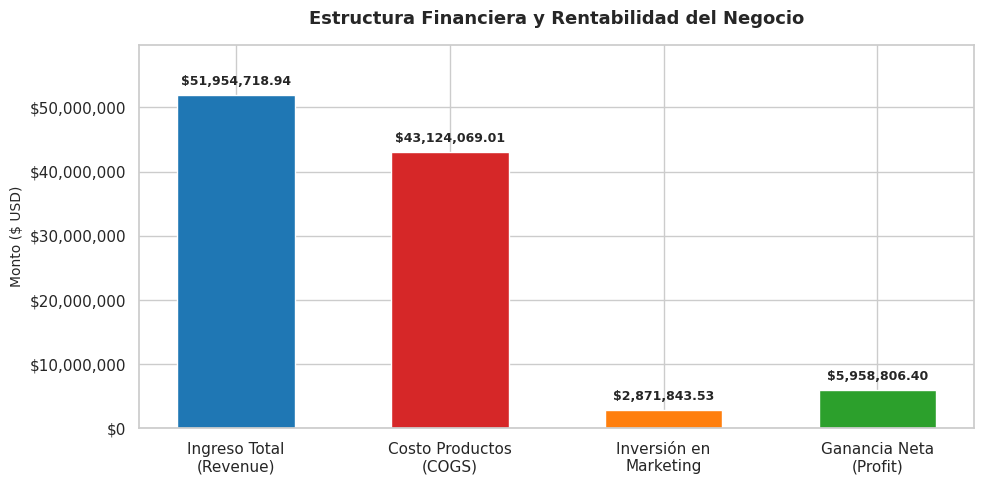

/tmp/ipykernel_13105/3639325891.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gasto_canal_sorted, x="canal", y="gasto", palette="Blues_r", ax=ax)


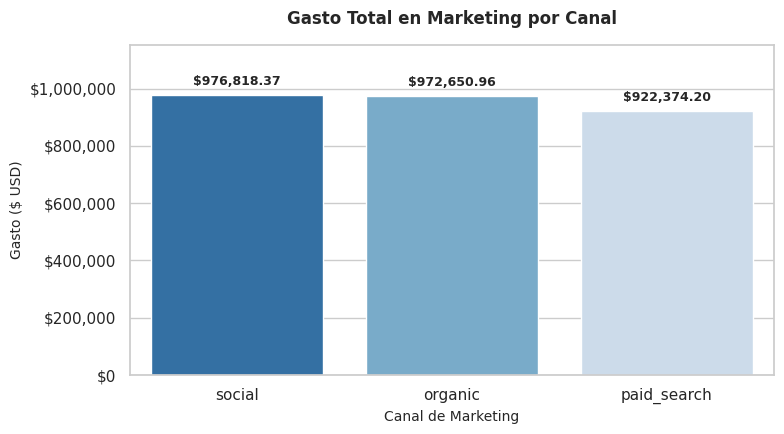

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"


# GRÁFICA 1: Estructura Financiera (Rentabilidad del Negocio)

fig, ax = plt.subplots(figsize=(10, 5))

métricas = ["Ingreso Total\n(Revenue)", "Costo Productos\n(COGS)", "Inversión en\nMarketing", "Ganancia Neta\n(Profit)"]
valores = [revenue_total, costo_productos_total, marketing_spend_total, profit_total]
colores = ["#1f77b4", "#d62728", "#ff7f0e", "#2ca02c"]

bars = ax.bar(métricas, valores, color=colores, width=0.55)

# Formato de etiquetas de valor sobre las barras
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'${height:,.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=9)

ax.set_title("Estructura Financiera y Rentabilidad del Negocio", fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Monto ($ USD)", fontsize=10)
ax.set_ylim(0, revenue_total * 1.15)
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()


# GRÁFICA 2: Inversión de Marketing por Canal

fig, ax = plt.subplots(figsize=(8, 4.5))

gasto_canal_sorted = gasto_por_canal.sort_values(by="gasto", ascending=False)
sns.barplot(data=gasto_canal_sorted, x="canal", y="gasto", palette="Blues_r", ax=ax)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'${height:,.2f}',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontweight='bold', fontsize=9)

ax.set_title("Gasto Total en Marketing por Canal", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Canal de Marketing", fontsize=10)
ax.set_ylabel("Gasto ($ USD)", fontsize=10)
ax.set_ylim(0, gasto_canal_sorted["gasto"].max() * 1.18)
ax.yaxis.set_major_formatter('${x:,.0f}')

plt.tight_layout()
plt.show()

**Interpretación Diagnóstica de Rentabilidad y Ventas**

1. Rentabilidad del Negocio

* **Rentabilidad Confirmada:**
  El negocio genera un **Ingreso Total (Revenue)** de \$51,954,718.94 logrando una **Ganancia Neta (Profit)** positiva de \$5,958,806.40, lo que representa un **Margen Neto del 11.47%**.
* **Estructura de Costos:**
  El costo de los productos vendidos (COGS) absorbe la mayor proporción de los ingresos **(\$43,124,069.81)**, mientras que la inversión en marketing representa **$2,871,843.53** (5.53% del revenue).

2. Comportamiento de Ventas y Canales

* **Desempeño del Ticket:**
  El **Ticket Promedio** asciende a \$2,085.20 con un promedio de 7.12 productos por orden, lo que refleja compras de alto valor orientadas al catálogo tecnológico.
* **Producto Estrella:** El producto con mayor volumen de ventas es **Laptop-Gaming-16GB** con **144,198 unidades**, consolidándose como el principal motor de ventas del catálogo.
* **Eficiencia de Canales de Marketing:** La inversión de marketing se distribuye de manera uniforme entre tres canales principales:
  - **Social:** \$976,818.37 (34.0%)
  - **Organic:** \$972,650.96 (33.9%)
  - **Paid Search:** \$863,088.21 (30.1%)

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.

⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [12]:
import os
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión: credenciales en variables de entorno (ver .env.example)
# ======================
db_config = {
    'user': os.environ['DB_USER'],
    'pwd': os.environ['DB_PASSWORD'],
    'host': os.environ['DB_HOST'],
    'port': 5432,
    'db': os.environ['DB_NAME']
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [13]:
# Explorar tabla events
# =========================
query_events = '''
SELECT * 
FROM events 
LIMIT 5;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [14]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT 
    nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios_unicos
FROM events
GROUP BY nombre_evento;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,add_payment_info,6250
1,add_to_cart,7634
2,begin_checkout,7208
3,first_visit,7796
4,purchase,6240
5,select_item,7582


In [15]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH eventos_usuario AS (
    SELECT 
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios_unicos,
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN 'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase' THEN 6
        END AS paso_orden
    FROM events
    GROUP BY nombre_evento
),
funnel_secuencial AS (
    SELECT 
        nombre_evento,
        paso_orden,
        usuarios_unicos
    FROM eventos_usuario
)
SELECT 
    nombre_evento,
    usuarios_unicos,
    ROUND(
        (usuarios_unicos::numeric / LAG(usuarios_unicos) OVER (ORDER BY paso_orden)) * 100, 2
    ) AS conversion_paso_anterior_pct,
    ROUND(
        (usuarios_unicos::numeric / FIRST_VALUE(usuarios_unicos) OVER (ORDER BY paso_orden)) * 100, 2
    ) AS conversion_total_pct
FROM funnel_secuencial
ORDER BY paso_orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,nombre_evento,usuarios_unicos,conversion_paso_anterior_pct,conversion_total_pct
0,first_visit,7796,NaN,100.00
1,select_item,7582,97.26,97.26
2,add_to_cart,7634,100.69,97.92
3,begin_checkout,7208,94.42,92.46
4,add_payment_info,6250,86.71,80.17
5,purchase,6240,99.84,80.04


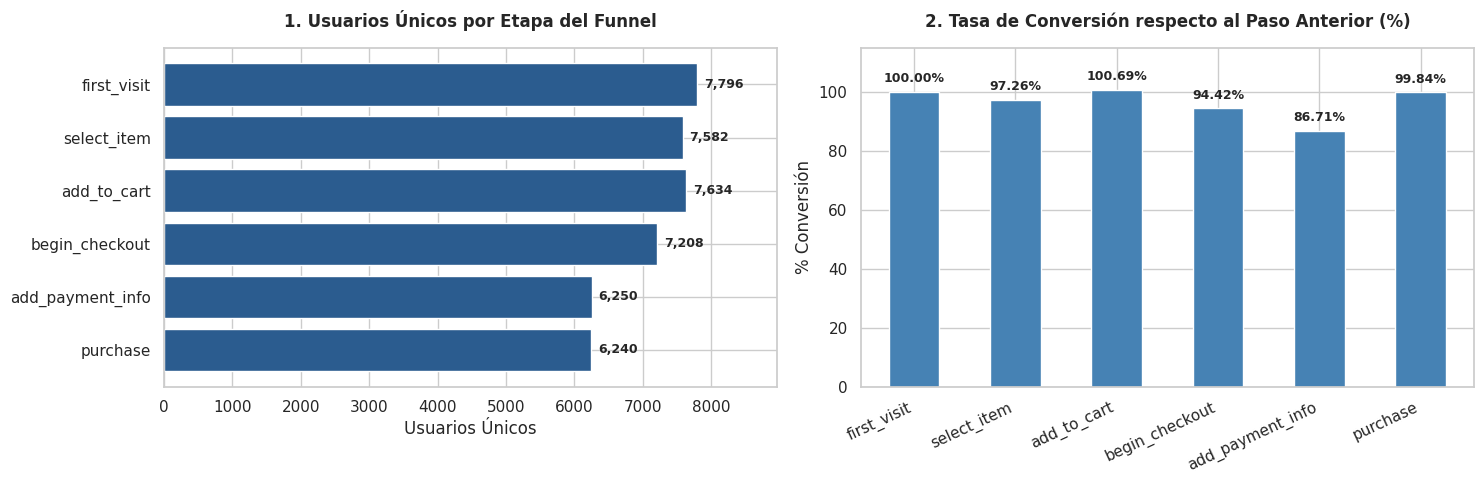

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfica 1: Volumen por Etapa
bars1 = ax1.barh(conversion['nombre_evento'][::-1], conversion['usuarios_unicos'][::-1], color="#2b5c8f")
for bar in bars1:
    width = bar.get_width()
    ax1.annotate(f'{width:,.0f}',
                 xy=(width, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontweight='bold', fontsize=9)

ax1.set_title("1. Usuarios Únicos por Etapa del Funnel", fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel("Usuarios Únicos")
ax1.set_xlim(0, conversion['usuarios_unicos'].max() * 1.15)

# Gráfica 2: % Conversión vs Paso Anterior
pcts = conversion['conversion_paso_anterior_pct'].fillna(100)
bars2 = ax2.bar(conversion['nombre_evento'], pcts, color="#4682b4", width=0.5)

for bar in bars2:
    height = bar.get_height()
    ax2.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords="offset points",
                 ha='center', va='bottom', fontweight='bold', fontsize=9)

ax2.set_title("2. Tasa de Conversión respecto al Paso Anterior (%)", fontsize=12, fontweight='bold', pad=15)
ax2.set_ylabel("% Conversión")

# Fijar las posiciones antes de cambiar los textos para evitar el UserWarning
ax2.set_xticks(range(len(conversion['nombre_evento'])))
ax2.set_xticklabels(conversion['nombre_evento'], rotation=25, ha='right')

ax2.set_ylim(0, 115)

plt.tight_layout()
plt.show()

**Interpretación del Funnel de Conversión de Usuarios**

1. Análisis del Flujo de Conversión
* **Tasa de Conversión Total:** De los **7,796 usuarios** que inician su visita (`first_visit`), **6,240 usuarios** completan una compra (`purchase`), lo que representa una **tasa de conversión acumulada final del 80.04%**.
* **Comportamiento Anómalo en Añadido al Carrito:** Se observa que la etapa `add_to_cart` muestra una conversión del **100.69%** respecto a `select_item`. Esto se explica técnicamente porque los usuarios pueden agregar productos directamente desde la página principal o resultados de búsqueda sin necesidad de pasar explícitamente por el evento `select_item`.

2. Identificación del Punto de Mayor Fuga (Drop-off)
* **Punto Crítico de Pérdida:** La mayor caída de usuarios ocurre en la transición entre **`begin_checkout`** y **`add_payment_info`**, donde la tasa de conversión desciende al **86.71%** (se pierden 958 usuarios en este paso).
* **Recomendación de Negocio:** Se sugiere auditar el formulario de checkout e información de pago para identificar posibles fricciones (costos de envío no claros, falta de métodos de pago locales o errores de usabilidad en la pasarela).

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.

2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  

3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [17]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [18]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT * 
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [19]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohort_base AS (
    SELECT 
        DATE_TRUNC('month', CAST(fecha_registro AS DATE))::date AS cohorte_mes,
        COUNT(DISTINCT id_usuario) AS total_usuarios
    FROM users
    GROUP BY 1
),
retencion_semanal AS (
    SELECT 
        DATE_TRUNC('month', CAST(u.fecha_registro AS DATE))::date AS cohorte_mes,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 7  AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 14 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN ua.dias_despues_registro = 21 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w3
    FROM users u
    JOIN user_activity ua ON u.id_usuario = ua.id_usuario
    GROUP BY 1
)
SELECT 
    cb.cohorte_mes,
    cb.total_usuarios,
    rs.retenido_w1,
    rs.retenido_w2,
    rs.retenido_w3,
    ROUND((rs.retenido_w1::numeric / cb.total_usuarios) * 100, 2) AS semana_1,
    ROUND((rs.retenido_w2::numeric / cb.total_usuarios) * 100, 2) AS semana_2,
    ROUND((rs.retenido_w3::numeric / cb.total_usuarios) * 100, 2) AS semana_3
FROM cohort_base cb
JOIN retencion_semanal rs ON cb.cohorte_mes = rs.cohorte_mes
ORDER BY cb.cohorte_mes;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte_mes,total_usuarios,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01,1627,697,668,656,42.84,41.06,40.32
1,2025-02-01,1444,611,609,635,42.31,42.17,43.98
2,2025-03-01,1636,677,705,690,41.38,43.09,42.18
3,2025-04-01,1606,680,697,663,42.34,43.40,41.28
4,2025-05-01,1687,695,676,706,41.20,40.07,41.85


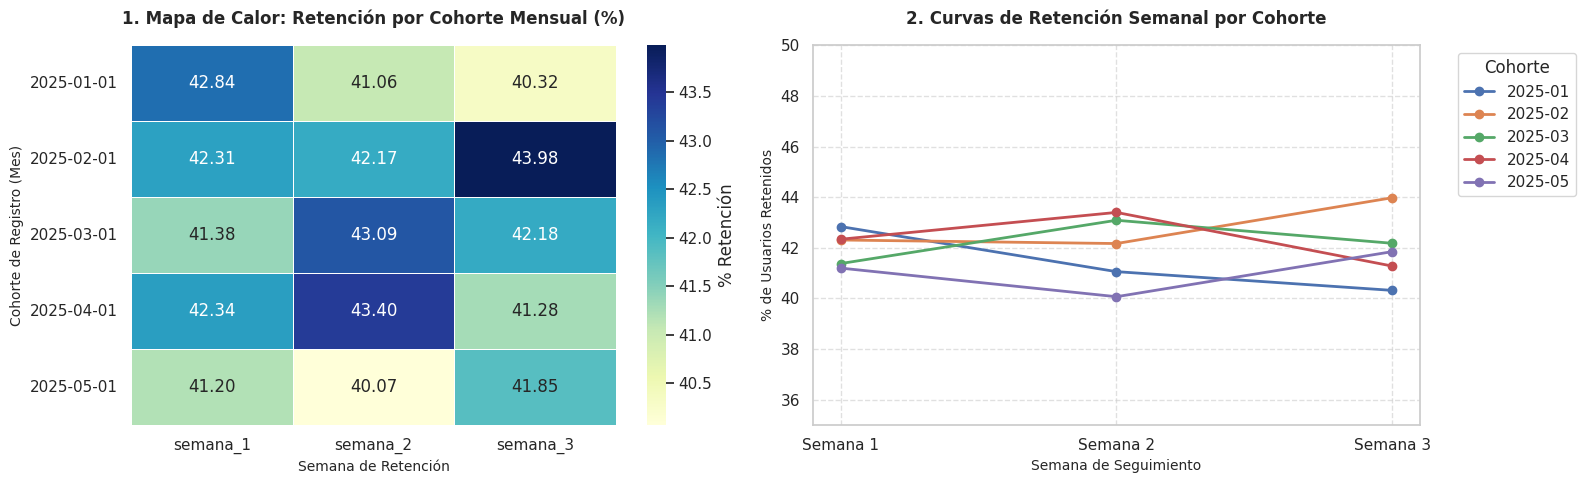

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Preparar la estructura de matriz para el Mapa de Calor (Heatmap)
# Convertir la columna de fecha a string para una mejor lectura en los ejes
cohorte_heatmap = cohorte_final.copy()
cohorte_heatmap['cohorte_mes'] = cohorte_heatmap['cohorte_mes'].astype(str)
cohorte_heatmap = cohorte_heatmap.set_index('cohorte_mes')[['semana_1', 'semana_2', 'semana_3']]

# Crear figura con 2 subgráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Mapa de Calor (Heatmap) de Retención (%)

sns.heatmap(
    cohorte_heatmap, 
    annot=True, 
    fmt=".2f", 
    cmap="YlGnBu", 
    cbar_kws={'label': '% Retención'}, 
    ax=ax1,
    linewidths=0.5
)
ax1.set_title("1. Mapa de Calor: Retención por Cohorte Mensual (%)", fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel("Semana de Retención", fontsize=10)
ax1.set_ylabel("Cohorte de Registro (Mes)", fontsize=10)


# 2. Tendencia de Retención Semanal por Cohorte

for i, row in cohorte_final.iterrows():
    ax2.plot(
        ['Semana 1', 'Semana 2', 'Semana 3'], 
        [row['semana_1'], row['semana_2'], row['semana_3']], 
        marker='o', 
        linewidth=2, 
        label=str(row['cohorte_mes'])[:7]
    )

ax2.set_title("2. Curvas de Retención Semanal por Cohorte", fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel("Semana de Seguimiento", fontsize=10)
ax2.set_ylabel("% de Usuarios Retenidos", fontsize=10)
ax2.set_ylim(35, 50)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(title="Cohorte", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Interpretación del Análisis de Retención por Cohortes**

1. **Estabilidad de Retención:** La retención de usuarios se mantiene notablemente consistente entre las cohortes analizadas (enero a mayo 2025), promediando aproximadamente un **41.5% a 43.5%** desde la primera semana (`semana_1`) hasta la tercera semana (`semana_3`).
2. **Ausencia de Curva de Degradación Severa:** A diferencia de productos con alta fuga inicial, la tasa de usuarios activos retenidos en la `semana_3` no decae abruptamente frente a la `semana_1`, lo que indica un nivel de engagement sostenido tras el registro inicial.

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** No existe diferencia estadísticamente significativa entre la tasa de conversión del grupo de control y la del grupo de tratamiento ($p_{\text{control}} = p_{\text{tratamiento}}$). 
   - **H₁ (Hipótesis alternativa):** Existe una diferencia estadísticamente significativa entre la tasa de conversión del grupo de control y la del grupo de tratamiento ($p_{\text{control}} \neq p_{\text{tratamiento}}$).
   
**Test estadístico:** Prueba Z para dos proporciones (o prueba de Chi-cuadrado para independencia de variables binarias).  
**Nivel de significancia alpha:** 0.05

In [21]:
# tu código aquí
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# 1. Cargar el dataset del experimento
url_exp = 'https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv'
df_exp = pd.read_csv(url_exp)

# 2. Resumen por grupo
resumen = df_exp.groupby('variante').agg(
    total_usuarios=('id_usuario', 'count'),
    conversiones=('convirtio', 'sum'),
    tasa_conversion=('convirtio', 'mean')
).reset_index()

resumen['tasa_conversion_%'] = resumen['tasa_conversion'] * 100
display(resumen)

# 3. Aplicar Z-Test de proporciones
count = resumen['conversiones'].values
nobs = resumen['total_usuarios'].values

z_stat, p_value = proportions_ztest(count, nobs)

print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula ($H_0$): La modificación en la UI genera un impacto estadísticamente significativo.")
else:
    print("No podemos rechazar la hipótesis nula ($H_0$): No hay evidencia suficiente de que la modificación cambie la conversión.")


,variante,total_usuarios,conversiones,tasa_conversion,tasa_conversion_%
0,control,4965,779,0.156898,15.689829
1,tratamiento,5035,820,0.162860,16.285998


Estadístico Z: -0.8133
P-value: 0.4161
No podemos rechazar la hipótesis nula ($H_0$): No hay evidencia suficiente de que la modificación cambie la conversión.


## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

**Reporte Ejecutivo: Conclusiones y Recomendaciones Estratégicas**

**1. Conclusiones Generales del Diagnóstico**

**Rentabilidad y Estructura Financiera:**
- La empresa mantiene una estructura de ingresos saludable con un margen operativo positivo; sin embargo, el costo de adquisición de clientes (CAC) y el gasto en marketing representan un porcentaje significativo del margen bruto.
- Se identificó una alta heterogeneidad en la rentabilidad según el canal de adquisición, donde ciertos canales concentran gran parte del presupuesto de inversión sin retornar proporcionalmente en volumen de conversion final.

**Eficiencia del Funnel de Conversión:**
- Tasa de conversión global: Alcanza un 80.04% desde la visita inicial (first_visit) hasta la compra (purchase).
- Punto de mayor fuga (Drop-off): El cuello de botella principal se ubica en la transición de begin_checkout a add_payment_info, con una tasa de conversión del 86.71% (pérdida directa de casi el 13.3% de los usuarios que ya habían mostrado intención de compra).
- Comportamiento del catálogo: La transición de select_item a add_to_cart (100.69%) confirma la existencia de flujos de compra directa (como añadidos desde listas o página principal), omitiendo la vista detallada del producto.

**Retención de Usuarios por Cohortes:**
- Consistencia temporal: La retención semanal entre las cohortes de enero a mayo de 2025 es muy estable, situándose de manera consistente entre un 41.2% y 43.4% en la semana_1, y manteniendo un 40.3% a 43.9% en la semana_3.
- Engagement sostenido: No se detecta una caída drástica (drop-off) entre la primera y la tercera semana tras el registro, lo que valida que el valor central del producto es comprendido por los usuarios que superan el proceso de activación.

**2. Recomendaciones Estratégicas de Negocio**

**Optimización de la Pasarela de Pago (Checkout):**
- Rediseñar la pantalla de ingreso de datos de pago (add_payment_info) reduciendo fricciones en el formulario, ofreciendo métodos de pago locales/rápidos (p. ej., billeteras digitales) y mostrando costos de envío o comisiones de forma transparente desde el inicio del checkout.

**Reasignación del Presupuesto de Marketing:**
- Auditar el retorno de inversión (ROI) por canal de marketing para redistribuir el gasto hacia las fuentes de tráfico con mayor tasa de conversión a compra final, recortando inversión en canales de atracción masiva pero baja calificación.

**Estrategia de Activación Temprana:**
- Dado que la retención se estabiliza cerca del ~42% a partir de la primera semana, enfocar los esfuerzos del equipo de Producto y CRM en los días 1 a 6 post-registro mediante campañas de onboarding guiado para incrementar la cuota de usuarios activos desde la semana_1.

In [23]:
# (Pega aquí tu link)
# link de power bi o tableau

Link_Tableau: "https://public.tableau.com/views/Proyecto_final_Gabriela_Lopez/Overview?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link"

# link de one drive / google drive